# Pré-processamento e CNN

## Importações

In [1]:
import json
import random
import numpy as np
import torch
import matplotlib.pyplot as plt

from pathlib import Path
from torch.utils.data import DataLoader

from nucleo import (
    transformacao, dividir_arquivos, DatasetReconstrucao, AutoencoderCNN,
    calibrar_lambda, treinar,
    SEED, SEED_VALIDACAO, TEMPERATURA_PADRAO
)


## Configurações

In [2]:
PASTA_TILE = Path("datasets/MVTecAD/tile")
PASTA_MODELOS = Path("modelos")

# Otimizados
BATCH_SIZE = 8
EPOCAS = 60
TAXA_APRENDIZADO = 0.0010412465683503824
WEIGHT_DECAY = 3.2090919114965903e-07
PATIENCE = 8

TEMPERATURA =  0.006078041671733781     # suavizacao da caracteristica de Euler

# Peso do termo de Euler. Se LAMBDA_EULER = None, ele é calibrado para que o termo de Euler valha PESO_EULER_RELATIVO x o MSE na escala inicial dos erros.
PESO_EULER_RELATIVO = 0.010224964732369961
LAMBDA_EULER = None

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

dispositivo = torch.device("cuda" if torch.cuda.is_available() else "cpu")


## Pré-processamento

Treinamento: 195
Validacao: 35


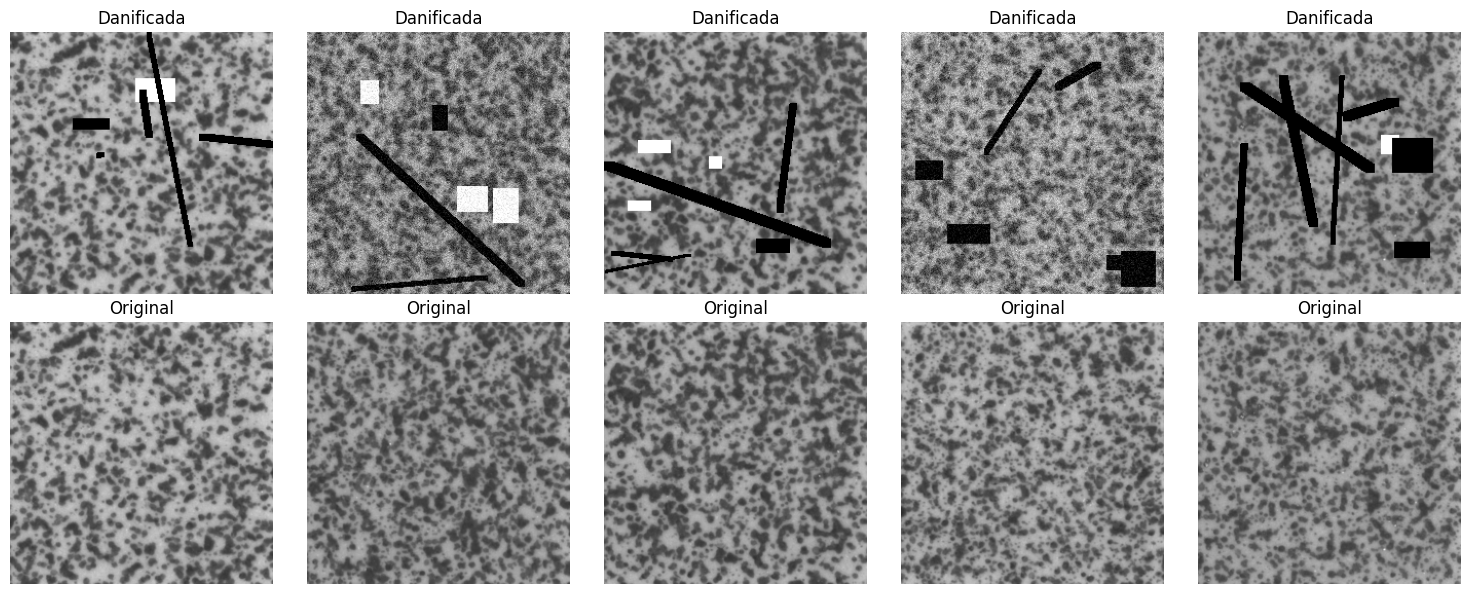

In [3]:
# Divisão do dataset. OBS.:
# Treinamento : dano NOVO a cada acesso (aumento de dados)
# Validacao   : danos FIXOS (curva de validacao comparavel entre epocas)

arquivos_treino, arquivos_validacao = dividir_arquivos(PASTA_TILE / "train" / "good", seed=SEED)

dataset_treino = DatasetReconstrucao(arquivos_treino, transformacao)
dataset_validacao = DatasetReconstrucao(arquivos_validacao, transformacao, danos_fixos=True, semente=SEED_VALIDACAO)

loader_treino = DataLoader(dataset_treino, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
loader_validacao = DataLoader(dataset_validacao, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print("Treinamento:", len(dataset_treino))
print("Validacao:", len(dataset_validacao))

# Visualização de pares

entrada, alvo = next(iter(loader_treino))
fig, eixos = plt.subplots(2, 5, figsize=(15, 6))
for i in range(5):
    eixos[0, i].imshow(entrada[i, 0], cmap="gray", vmin=0, vmax=1)
    eixos[0, i].set_title("Danificada")
    eixos[1, i].imshow(alvo[i, 0], cmap="gray", vmin=0, vmax=1)
    eixos[1, i].set_title("Original")
    eixos[0, i].axis("off")
    eixos[1, i].axis("off")

plt.tight_layout()
plt.show()


## Calibração do peso do termo de euler

In [4]:
if LAMBDA_EULER is None:
    lambda_euler, mse_ref, euler_ref = calibrar_lambda(loader_treino, PESO_EULER_RELATIVO, temperatura=TEMPERATURA)
    print(f"MSE (danificada vs original)      : {mse_ref:.5f}")
    print(f"|dChi| (danificada vs original)   : {euler_ref:.2f}")

else:
    lambda_euler = LAMBDA_EULER

print(f"lambda_euler = {lambda_euler:.6f}")


MSE (danificada vs original)      : 0.01767
|dChi| (danificada vs original)   : 737.54
lambda_euler = 0.000000


## Rede - Autoencoder convolucional com característica de euler
perda = MSE + lambda * media(|chi(reconstruida) - chi(original)|)

In [5]:
torch.manual_seed(SEED)

modelo = AutoencoderCNN().to(dispositivo)

print("Parametros:", sum(p.numel() for p in modelo.parameters()))

historico = treinar(
    modelo,
    loader_treino,
    loader_validacao,
    lambda_euler=lambda_euler,
    epocas=EPOCAS,
    taxa_aprendizado=TAXA_APRENDIZADO,
    dispositivo=dispositivo,
    caminho_modelo=PASTA_MODELOS / "autoencoder_euler.pth",
    temperatura=TEMPERATURA,
    weight_decay=WEIGHT_DECAY,
    patience=PATIENCE    
)


Parametros: 136609
Epoca 001/60 | Treino: 0.00935 | Validacao: 0.01073 | MSE val: 0.01055 | |dChi| val: 766.10 | 34s *
Epoca 002/60 | Treino: 0.00490 | Validacao: 0.00523 | MSE val: 0.00517 | |dChi| val: 263.56 | 32s *
Epoca 003/60 | Treino: 0.00420 | Validacao: 0.00384 | MSE val: 0.00379 | |dChi| val: 190.72 | 33s *
Epoca 004/60 | Treino: 0.00393 | Validacao: 0.00431 | MSE val: 0.00425 | |dChi| val: 253.30 | 29s
Epoca 005/60 | Treino: 0.00369 | Validacao: 0.00330 | MSE val: 0.00326 | |dChi| val: 166.93 | 27s *
Epoca 006/60 | Treino: 0.00330 | Validacao: 0.00318 | MSE val: 0.00314 | |dChi| val: 133.03 | 34s *
Epoca 007/60 | Treino: 0.00338 | Validacao: 0.00323 | MSE val: 0.00320 | |dChi| val: 118.50 | 32s
Epoca 008/60 | Treino: 0.00319 | Validacao: 0.00304 | MSE val: 0.00301 | |dChi| val: 117.55 | 30s *
Epoca 009/60 | Treino: 0.00305 | Validacao: 0.00290 | MSE val: 0.00287 | |dChi| val: 121.56 | 28s *
Epoca 010/60 | Treino: 0.00319 | Validacao: 0.00305 | MSE val: 0.00302 | |dChi| val: 

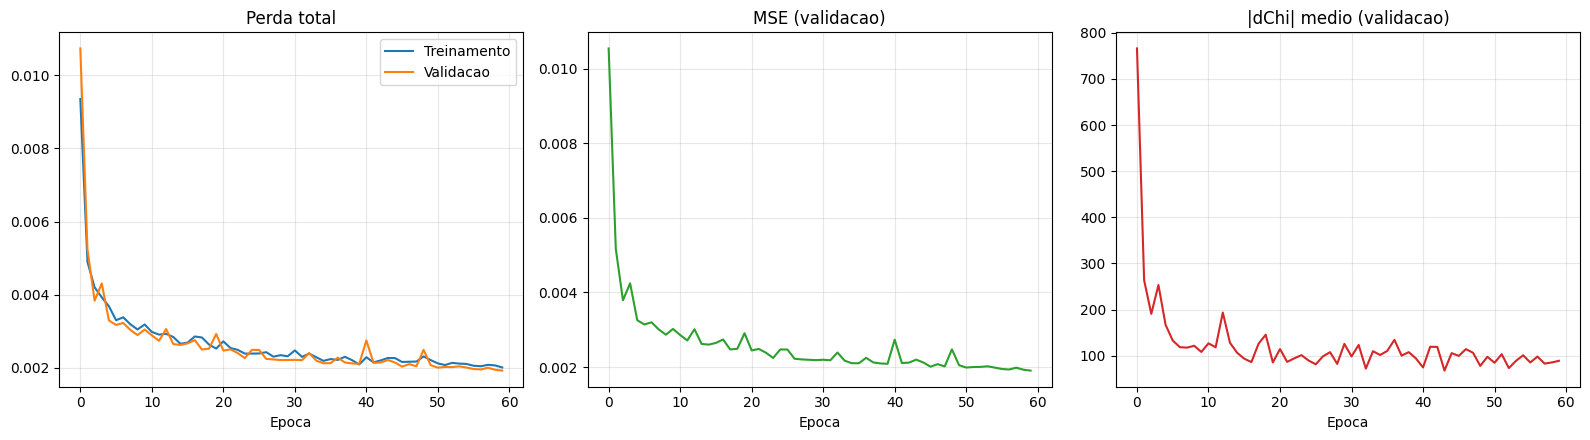

In [6]:
# Visualização das curvas de treinamento

fig, eixos = plt.subplots(1, 3, figsize=(16, 4.5))

eixos[0].plot(historico["treino"], label="Treinamento")
eixos[0].plot(historico["validacao"], label="Validacao")
eixos[0].set_title("Perda total")

eixos[1].plot(historico["mse_validacao"], color="tab:green")
eixos[1].set_title("MSE (validacao)")

eixos[2].plot(historico["euler_validacao"], color="tab:red")
eixos[2].set_title("|dChi| medio (validacao)")

for eixo in eixos:
    eixo.set_xlabel("Epoca")
    eixo.grid(alpha=0.3)

eixos[0].legend()

plt.tight_layout()
plt.show()


In [7]:
# Baseline - modelo sem euler

TAXA_APRENDIZADO_2 = 0.0017923986698147982
WEIGHT_DECAY_2 = 4.6658962792616827e-08
PATIENCE_2 = 20
BATCH_SIZE_2 = 8
PESO_RELATIVO_2 = 0.0
TEMPERATURA_2 = 0.02


torch.manual_seed(SEED)
modelo_base = AutoencoderCNN().to(dispositivo)
random.seed(SEED)

historico_base = treinar(
    modelo_base,
    loader_treino,
    loader_validacao,
    lambda_euler=0.0,
    epocas=EPOCAS,
    taxa_aprendizado=TAXA_APRENDIZADO_2,
    dispositivo=dispositivo,
    caminho_modelo=PASTA_MODELOS / "autoencoder_baseline.pth",
    temperatura=TEMPERATURA_2,
    weight_decay=WEIGHT_DECAY_2,
    patience=PATIENCE_2
)


Epoca 001/60 | Treino: 0.00835 | Validacao: 0.01006 | MSE val: 0.01006 | |dChi| val: 3004.07 | 30s *
Epoca 002/60 | Treino: 0.00447 | Validacao: 0.00447 | MSE val: 0.00447 | |dChi| val: 231.89 | 28s *
Epoca 003/60 | Treino: 0.00404 | Validacao: 0.00360 | MSE val: 0.00360 | |dChi| val: 350.26 | 27s *
Epoca 004/60 | Treino: 0.00371 | Validacao: 0.00332 | MSE val: 0.00332 | |dChi| val: 319.30 | 27s *
Epoca 005/60 | Treino: 0.00348 | Validacao: 0.00316 | MSE val: 0.00316 | |dChi| val: 348.89 | 25s *
Epoca 006/60 | Treino: 0.00316 | Validacao: 0.00432 | MSE val: 0.00432 | |dChi| val: 172.20 | 25s
Epoca 007/60 | Treino: 0.00339 | Validacao: 0.00303 | MSE val: 0.00303 | |dChi| val: 242.49 | 27s *
Epoca 008/60 | Treino: 0.00305 | Validacao: 0.00464 | MSE val: 0.00464 | |dChi| val: 145.64 | 27s
Epoca 009/60 | Treino: 0.00299 | Validacao: 0.00281 | MSE val: 0.00281 | |dChi| val: 274.92 | 30s *
Epoca 010/60 | Treino: 0.00306 | Validacao: 0.00306 | MSE val: 0.00306 | |dChi| val: 144.72 | 26s
Epoca